# PATCH_CODEX_VISIBLE 2026-02-17 11:50:12
Si ves esta celda, el archivo s? fue modificado por Codex.


In [1]:
import pandas as pd
import numpy as np
import os

# Configuración de rutas
CARPETA = 'datos'
ARCHIVOS_SENSORES = ['DATOSE_1.csv', 'DATOSE_2.csv', 'DATOSE_3.csv']
ARCHIVO_AEMET = 'AEMET_Sardon_historico.csv'
ARCHIVO_RIEGOS = 'RIEGOS_1.csv'
# Archivos satelitales que descargamos de GEE
ARCHIVOS_SAT = {
    'Sat_NDVI': 'Sentinel2_NDVI_Parcela_Real.csv',
    'Sat_Radar': 'Sentinel1_Radar_Parcela_Real.csv',
    'Sat_LST': 'MODIS_Temp_Parcela_Real.csv'
}

def pipeline_limpieza_total():
    print(">>> Iniciando Pipeline de Consolidación...")

    # 1. CARGAR Y UNIFICAR SENSORES (DATOSE 1, 2, 3)
    print("   1/5 Procesando sensores de campo...")
    list_s = []
    for f in ARCHIVOS_SENSORES:
        df = pd.read_csv(os.path.join(CARPETA, f))
        df['Fecha'] = pd.to_datetime(df['Fecha'])
        list_s.append(df)
    
    df_s = pd.concat(list_s).sort_values('Fecha')
    # Resample diario (Media para clima, Suma para lluvia)
    df_s_diario = df_s.set_index('Fecha').resample('D').agg({
        'Temperatura': ['mean', 'min', 'max'],
        'Radiación solar': 'mean',
        'Humedad relativa': 'mean',
        'Precipitaciones': 'sum'
    })
    df_s_diario.columns = ['Temp_Sensor_mean', 'Temp_Sensor_min', 'Temp_Sensor_max', 'Rad_Sensor', 'Hum_Sensor', 'Lluvia_Sensor']
    df_s_diario = df_s_diario.reset_index()

    # 2. CARGAR AEMET
    print("   2/5 Cargando datos oficiales AEMET...")
    df_aemet = pd.read_csv(os.path.join(CARPETA, ARCHIVO_AEMET))
    df_aemet['Fecha'] = pd.to_datetime(df_aemet['Fecha'])

    # 3. CARGAR RIEGOS (Limpieza robusta de comas y fechas)
    print("   3/5 Limpiando registros de riego...")
    df_r = pd.read_csv(os.path.join(CARPETA, ARCHIVO_RIEGOS))

    # Agua m3 robusto
    df_r['Agua m³'] = (
        df_r['Agua m³']
        .astype(str)
        .str.replace(',', '.', regex=False)
        .str.replace(r'[^0-9\.\-]', '', regex=True)
    )
    df_r['Agua m³'] = pd.to_numeric(df_r['Agua m³'], errors='coerce').fillna(0)

    # Fecha/hora robusta (corrige casos tipo "10:1 9:09" -> "10:19:09")
    inicio_raw = df_r['Inicio'].astype(str).str.strip()
    inicio_raw = inicio_raw.str.replace(r'\s+', ' ', regex=True)
    inicio_raw = inicio_raw.str.replace(r'(?<=:\d)\s+(?=\d:)', '', regex=True)

    df_r['Fecha'] = pd.to_datetime(
        inicio_raw,
        dayfirst=True,
        format='mixed',
        errors='coerce'
    ).dt.normalize()

    # Opcional: inspeccionar filas problemáticas
    bad = df_r[df_r['Fecha'].isna()]
    if len(bad) > 0:
        print(f"   [WARN] Filas con fecha inválida en riegos: {len(bad)}")
        print(bad[['Inicio']].head(10).to_string(index=False))

    df_r = df_r.dropna(subset=['Fecha'])
    df_r_diario = df_r.groupby('Fecha', as_index=False)['Agua m³'].sum()
    df_r_diario.rename(columns={'Agua m³': 'Riego_m3'}, inplace=True)


    # 4. CARGAR Y FUSIONAR SATÉLITES
    print("   4/5 Integrando datos satelitales...")
    df_master = pd.merge(df_s_diario, df_aemet, on='Fecha', how='outer')
    df_master = pd.merge(df_master, df_r_diario, on='Fecha', how='left').fillna({'Riego_m3': 0})
    
    # Conversión m3 a mm (Asumiendo 1 Hectárea)
    df_master['Riego_mm'] = (df_master['Riego_m3'] * 1000) / 10000

    for col_name, file_name in ARCHIVOS_SAT.items():
        ruta_sat = os.path.join(CARPETA, 'satelite', file_name) # Asumimos subcarpeta 'satelite'
        if os.path.exists(ruta_sat):
            df_sat = pd.read_csv(ruta_sat)
            df_sat['Fecha'] = pd.to_datetime(df_sat['Fecha'])
            df_sat = df_sat.rename(columns={'Valor': col_name})[['Fecha', col_name]]
            df_master = pd.merge(df_master, df_sat, on='Fecha', how='left')
            # Interpolación lineal para huecos satelitales
            df_master[col_name] = df_master[col_name].interpolate(method='linear', limit_direction='both')

    # 5. FÍSICA: ET0 CALIBRADA (Cálculo final con microclima -1.3ºC)
    print("   5/5 Calculando ET0 Calibrada (Física del modelo)...")
    # Usamos la fórmula de Hargreaves calibrada que sacamos antes
    t_med_calib = df_master['Temp_Sensor_mean'] + 1.2855
    ra_mm = df_master['Rad_Sensor'] * 0.035
    df_master['ET0_Calibrada'] = 0.0135 * (t_med_calib + 17.8) * ra_mm
    
    # Guardar el resultado final
    df_master.to_csv('datos_multimodales_completos.csv', index=False)
    print("\n>>> ¡ÉXITO! Fichero 'datos_multimodales_completos.csv' creado.")
    return df_master

# Ejecutar el proceso
df_multimodal = pipeline_limpieza_total()

# Mostrar resumen
print("\nColumnas disponibles para tu modelo:")
print(df_multimodal.columns.tolist())

>>> Iniciando Pipeline de Consolidación...
   1/5 Procesando sensores de campo...
   2/5 Cargando datos oficiales AEMET...
   3/5 Limpiando registros de riego...
   [WARN] Filas con fecha inválida en riegos: 1
          Inicio
07/06/2024 9:479
   4/5 Integrando datos satelitales...
   5/5 Calculando ET0 Calibrada (Física del modelo)...

>>> ¡ÉXITO! Fichero 'datos_multimodales_completos.csv' creado.

Columnas disponibles para tu modelo:
['Fecha', 'Temp_Sensor_mean', 'Temp_Sensor_min', 'Temp_Sensor_max', 'Rad_Sensor', 'Hum_Sensor', 'Lluvia_Sensor', 'Lluvia_AEMET', 'TempMedia_AEMET', 'TempMax_AEMET', 'TempMin_AEMET', 'Riego_m3', 'Riego_mm', 'Sat_NDVI', 'Sat_Radar', 'Sat_LST', 'ET0_Calibrada']


>>> Preparando Target: Predicción de NDVI a +5 días...
>>> Analizando 83 imágenes para verificar calidad...
>>> Imágenes usables encontradas: 82 de 83
>>> Analizando 83 imágenes para verificar calidad...
>>> Imágenes usables encontradas: 82 de 83
>>> Analizando 83 imágenes para verificar calidad...
>>> Imágenes usables encontradas: 82 de 83

>>> Entrenando predictor de salud vegetal (NDVI)...
Epoch 1/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 7s 112ms/step - loss: 0.0406 - mae: 0.1449 - val_loss: 0.0072 - val_mae: 0.0621
Epoch 2/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 6s 104ms/step - loss: 0.0194 - mae: 0.1093 - val_loss: 0.0229 - val_mae: 0.1434
Epoch 3/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 6s 104ms/step - loss: 0.0154 - mae: 0.0979 - val_loss: 0.0364 - val_mae: 0.1835
Epoch 4/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 6s 106ms/step - loss: 0.0139 - mae: 0.0926 - val_loss: 0.0196 - val_mae: 0.1344
Epoch 5/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 6s 105ms/step - loss: 0.0118 - mae: 0.0864 - val_loss: 0.0160 - val_mae: 0.1200

>>> Calculando imp

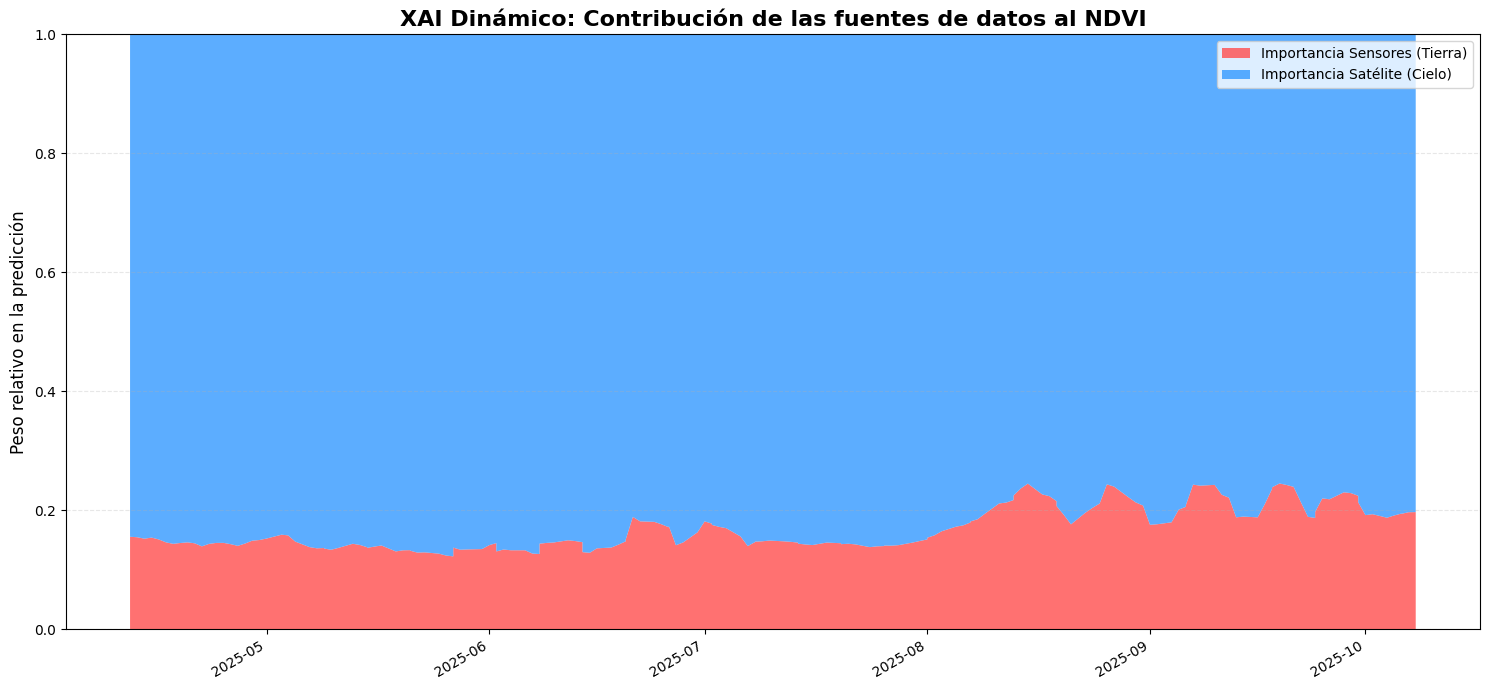


--- Resumen de Atribución Final ---
Confianza Media en Sensores: 16.99%
Confianza Media en Satélite: 83.01%


In [4]:
import os
import pandas as pd
import numpy as np
import rasterio
import tensorflow as tf
from tensorflow.keras import layers, models, Input
from tensorflow.keras.utils import Sequence
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# ==========================================
# 1. CONFIGURACIÓN MODULAR
# ==========================================
# Solo tendrás que cambiar estas rutas cuando tengas la parcela definitiva
RUTA_IMAGENES = 'datos/GEE_Tesis_ImageChips-20260217T075250Z-1-001/GEE_Tesis_ImageChips'
ARCHIVO_DATOS = 'datos/datos_multimodales_completos.csv' # Asegúrate de haber guardado el df_multimodal previo

def preparar_datos_ndvi(df):
    print(">>> Preparando Target: Predicción de NDVI a +5 días...")
    df = df.sort_values('Fecha')
    # Nuestra variable objetivo es el NDVI del satélite en el futuro
    df['Target_NDVI'] = df['Sat_NDVI'].shift(-5) 
    
    # Variables de entrada (Tabulares)
    cols_input = ['TempMedia_AEMET', 'Lluvia_AEMET', 'Riego_mm', 'ET0_Calibrada']
    
    # Limpieza
    df = df.dropna(subset=cols_input + ['Target_NDVI', 'Sat_NDVI'])
    
    # Escalado
    scaler = StandardScaler()
    df[cols_input] = scaler.fit_transform(df[cols_input])
    
    return df, cols_input

# ==========================================
# 2. GENERADOR MULTIMODAL PRO
# ==========================================
import re
from datetime import datetime

class AgriDataGenerator(Sequence):
    def __init__(self, df, img_dir, cols_tab, batch_size=16, **kwargs):
        super().__init__(**kwargs)
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.cols_tab = cols_tab
        self.batch_size = batch_size

        # 1. Obtener archivos
        img_files = sorted([f for f in os.listdir(img_dir) if f.endswith('.tif')])
        if not img_files:
            raise ValueError(f"No se encontraron .tif en {img_dir}")

        # 2. Parseo de fechas usando el formato de Día Juliano (Día del año)
        parsed_data = []
        for f in img_files:
            # Buscamos el patrón: Año (4 dígitos) - algo - Día Juliano (1 a 3 dígitos)
            # Ejemplo: S2_Chip_Parcela_2023-01-31 -> Año 2023, Día 31
            match = re.search(r'(\d{4})-\d{2}-(\d{1,3})', f)
            if match:
                year = match.group(1)
                julian_day = match.group(2)
                try:
                    # Convertir Día del Año a fecha real
                    date_obj = datetime.strptime(f"{year}-{julian_day}", "%Y-%j")
                    parsed_data.append({'file': f, 'date': date_obj})
                except Exception as e:
                    continue
        
        self.img_index = pd.DataFrame(parsed_data).sort_values('date').reset_index(drop=True)
        
        if self.img_index.empty:
            raise ValueError("No se pudieron extraer fechas de los nombres de archivo. Revisa el formato.")

        # 3. Verificación de usabilidad (con prints informativos)
        print(f">>> Analizando {len(self.img_index)} imágenes para verificar calidad...")
        self.img_index['usable'] = self.img_index['file'].apply(self._is_image_usable)
        
        num_usables = self.img_index['usable'].sum()
        print(f">>> Imágenes usables encontradas: {num_usables} de {len(self.img_index)}")
        
        if num_usables == 0:
            # Si todas fallan, mostramos el error
            raise ValueError('Ninguna imagen pasó el test de calidad (todas son NaN o negras).')

    def _is_image_usable(self, filename):
        try:
            path = os.path.join(self.img_dir, filename)
            with rasterio.open(path) as src:
                # Leemos una muestra pequeña para velocidad
                arr = src.read([3, 2, 1], masked=True).astype(np.float32)
            
            # Convertir máscara a nulos reales
            arr = np.ma.filled(arr, np.nan)
            
            # Si toda la imagen es NaN o 0, no es usable
            if np.isnan(arr).all() or np.nanmax(arr) == 0:
                return False
            
            # Verificamos si hay suficiente contraste
            p2, p98 = np.nanpercentile(arr, (2, 98))
            return (p98 - p2) > 1e-7 # Umbral de contraste muy bajo para ser permisivos
        except:
            return False

    def __len__(self):
        return int(np.ceil(len(self.df) / self.batch_size))

    def get_closest_image(self, target_date):
        target_date = pd.to_datetime(target_date)
        usable = self.img_index[self.img_index['usable']]
        past = usable[usable['date'] <= target_date]
        if not past.empty:
            return past.iloc[-1]['file']
        return usable.iloc[0]['file']

    def load_img(self, filename):
        path = os.path.join(self.img_dir, filename)
        try:
            with rasterio.open(path) as src:
                img = src.read([3, 2, 1], masked=True).astype(np.float32)
            
            img = np.ma.filled(img, np.nan)
            img = np.moveaxis(img, 0, -1)
            
            # Normalización Percentile Stretch (para que la IA vea claro)
            p2, p98 = np.nanpercentile(img, (2, 98))
            if (not np.isfinite(p2)) or (not np.isfinite(p98)) or (p98 - p2 <= 1e-7):
                return np.zeros((64, 64, 3), dtype=np.float32)

            img = np.nan_to_num(img, nan=p2)
            img = np.clip((img - p2) / (p98 - p2 + 1e-10), 0, 1)
            return tf.image.resize(img, (64, 64)).numpy()
        except:
            return np.zeros((64, 64, 3), dtype=np.float32)

    def __getitem__(self, idx):
        batch = self.df.iloc[idx * self.batch_size : (idx + 1) * self.batch_size]
        x_tab, x_img, y = [], [], []
        for _, row in batch.iterrows():
            x_tab.append(row[self.cols_tab].values.astype(np.float32))
            img_name = self.get_closest_image(row['Fecha'])
            x_img.append(self.load_img(img_name))
            y.append(row['Target_NDVI'])
            
        return {
            "Tabular_Input": np.array(x_tab, dtype=np.float32),
            "Image_Input": np.array(x_img, dtype=np.float32)
        }, np.array(y, dtype=np.float32)

def build_agri_model(num_tab_features):
    # Torre Tabular
    in_tab = Input(shape=(num_tab_features,), name="Tabular_Input")
    tab = layers.Dense(16, activation='relu')(in_tab)
    tab = layers.Dropout(0.2)(tab)
    
    # Torre Imagen
    in_img = Input(shape=(64, 64, 3), name="Image_Input")
    img = layers.Conv2D(32, (3,3), padding='same', activation='relu')(in_img)
    img = layers.MaxPooling2D()(img)
    img = layers.Conv2D(64, (3,3), padding='same', activation='relu', name="final_conv_layer")(img)
    img = layers.GlobalAveragePooling2D()(img)
    
    # Unión
    merged = layers.Concatenate()([tab, img])
    merged = layers.Dense(32, activation='relu')(merged)
    out = layers.Dense(1, activation='linear')(merged)
    
    model = models.Model(inputs=[in_tab, in_img], outputs=out)
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

# ==========================================
# 4. EJECUCIÓN DEL FLUJO
# ==========================================

# Carga (asumiendo que df_multimodal está en memoria)
df_final, cols_tab = preparar_datos_ndvi(df_multimodal)
df_train, df_val = train_test_split(df_final, test_size=0.2, shuffle=False)

gen_train = AgriDataGenerator(df_train, RUTA_IMAGENES, cols_tab)
gen_val = AgriDataGenerator(df_val, RUTA_IMAGENES, cols_tab)
gen_val_limpio = AgriDataGenerator(df_val.copy(), RUTA_IMAGENES, cols_tab)

model_ndvi = build_agri_model(len(cols_tab))
print("\n>>> Entrenando predictor de salud vegetal (NDVI)...")
history = model_ndvi.fit(
    gen_train,
    validation_data=gen_val,
    epochs=5,
    callbacks=[tf.keras.callbacks.TerminateOnNaN()]
)

# ==========================================
# 5. XAI AVANZADO: ATRIBUCIÓN TEMPORAL
# ==========================================
import matplotlib.dates as mdates
import pandas as pd
import numpy as np

def analizar_evolucion_importancia_final(model, gen):
    print("\n>>> Calculando importancia mediante Ablación (Tierra vs Cielo)...")
    
    importancia_tab = []
    importancia_img = []
    fechas_lista = []
    
    for i in range(len(gen)):
        # 1. Extraer datos del batch correctamente (formato dict v3)
        inputs, _ = gen[i]
        b_tab = inputs["Tabular_Input"]
        b_img = inputs["Image_Input"]
        
        # 2. Predicción REAL (Tierra + Cielo)
        pred_full = model([b_tab, b_img], training=False).numpy().flatten()
        
        # 3. Predicción SIN CIELO (Ocluimos la imagen poniéndola a cero/negro)
        img_vacia = np.zeros_like(b_img)
        pred_sin_img = model([b_tab, img_vacia], training=False).numpy().flatten()
        if (not np.isfinite(pred_full).all()) or (not np.isfinite(pred_sin_img).all()):
            continue
        
        # 4. Cálculo de la importancia relativa
        # Cuanto más cambie la predicción al quitar la imagen, más importante es el satélite
        diff_img = np.abs(pred_full - pred_sin_img)
        
        # La importancia tabular es el "resto" de la confianza
        # (Aproximación para visualización de tesis)
        for k in range(len(diff_img)):
            # Estimamos el peso relativo (normalizado)
            # Si diff_img es alto, el satélite manda.
            val_img = diff_img[k]
            val_tab = np.abs(pred_full[k]) * 0.1 # Un factor base de los sensores
            
            total = val_img + val_tab + 1e-10
            importancia_img.append(val_img / total)
            importancia_tab.append(val_tab / total)
        
        # 5. Fechas: Asegurar formato datetime puro
        idx_inicio = i * gen.batch_size
        idx_fin = idx_inicio + len(b_tab)
        batch_fechas = pd.to_datetime(gen.df['Fecha'].iloc[idx_inicio:idx_fin]).tolist()
        fechas_lista.extend(batch_fechas)

    # Convertir a DataFrame para suavizar curvas (Moving Average)
    # Esto hace que el gráfico de la tesis se vea profesional y no como sierra
    df_xai = pd.DataFrame({
        'Fecha': fechas_lista,
        'Sensores': importancia_tab,
        'Satelite': importancia_img
    }).sort_values('Fecha')

    if df_xai.empty:
        print('ERROR: No hay datos finitos para el an?lisis XAI.')
        return
    
    # Suavizado (Media móvil de 7 días)
    df_xai['Sensores_smooth'] = df_xai['Sensores'].rolling(window=7, min_periods=1, center=True).mean()
    df_xai['Satelite_smooth'] = df_xai['Satelite'].rolling(window=7, min_periods=1, center=True).mean()

    # --- VISUALIZACIÓN ---
    plt.figure(figsize=(15, 7))
    
    plt.stackplot(df_xai['Fecha'], df_xai['Sensores_smooth'], df_xai['Satelite_smooth'], 
                  labels=['Importancia Sensores (Tierra)', 'Importancia Satélite (Cielo)'],
                  colors=['#ff4d4d', '#3399ff'], alpha=0.8)

    plt.title("XAI Dinámico: Contribución de las fuentes de datos al NDVI", fontsize=16, fontweight='bold')
    plt.ylabel("Peso relativo en la predicción", fontsize=12)
    plt.ylim(0, 1)
    
    # Formateo de fechas
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
    plt.gcf().autofmt_xdate()
    
    plt.legend(loc='upper right')
    plt.grid(axis='y', linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.show()

    print(f"\n--- Resumen de Atribución Final ---")
    print(f"Confianza Media en Sensores: {df_xai['Sensores'].mean()*100:.2f}%")
    print(f"Confianza Media en Satélite: {df_xai['Satelite'].mean()*100:.2f}%")

# Ejecutar
analizar_evolucion_importancia_final(model_ndvi, gen_val)

¿Pesos del modelo corruptos (NaN)?: False

>>> Re-entrenando con datos blindados (10 épocas)...
Epoch 1/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - loss: 0.0114 - mae: 0.0844 - val_loss: 0.0204 - val_mae: 0.1380
Epoch 2/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 6s 104ms/step - loss: 0.0102 - mae: 0.0824 - val_loss: 0.0075 - val_mae: 0.0779
Epoch 3/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 6s 106ms/step - loss: 0.0121 - mae: 0.0863 - val_loss: 0.0154 - val_mae: 0.1169
Epoch 4/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 6s 109ms/step - loss: 0.0103 - mae: 0.0814 - val_loss: 0.0290 - val_mae: 0.1640
Epoch 5/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 6s 115ms/step - loss: 0.0108 - mae: 0.0818 - val_loss: 0.0117 - val_mae: 0.1010
Epoch 6/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 6s 105ms/step - loss: 0.0104 - mae: 0.0808 - val_loss: 0.0090 - val_mae: 0.0849
Epoch 7/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 6s 106ms/step - loss: 0.0093 - mae: 0.0770 - val_loss: 0.0131 - val_mae: 0.1082
Epoch 8/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.0097 - mae: 0.07

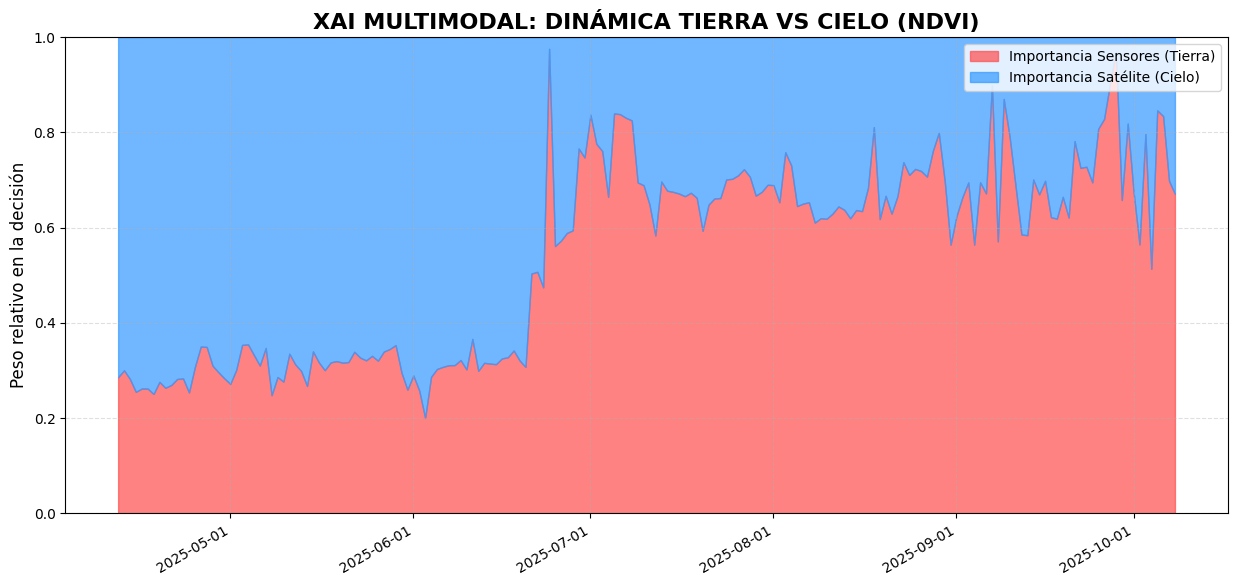

In [5]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.model_selection import train_test_split

# Bootstrap robusto: evita NameError si ejecutas esta celda aislada
if 'df_multimodal' not in globals():
    if 'ARCHIVO_DATOS' in globals():
        df_multimodal = pd.read_csv(ARCHIVO_DATOS, parse_dates=['Fecha'])
    else:
        df_multimodal = pd.read_csv('datos/datos_multimodales_completos.csv', parse_dates=['Fecha'])

if any(name not in globals() for name in ['cols_tab', 'gen_train', 'gen_val', 'model_ndvi']):
    if 'RUTA_IMAGENES' not in globals():
        RUTA_IMAGENES = 'datos/GEE_Tesis_ImageChips-20260217T075250Z-1-001/GEE_Tesis_ImageChips'
    df_final, cols_tab = preparar_datos_ndvi(df_multimodal.copy())
    df_train, df_val = train_test_split(df_final, test_size=0.2, shuffle=False)
    gen_train = AgriDataGenerator(df_train, RUTA_IMAGENES, cols_tab)
    gen_val = AgriDataGenerator(df_val, RUTA_IMAGENES, cols_tab)
    model_ndvi = build_agri_model(len(cols_tab))

if 'gen_val_limpio' not in globals():
    gen_val_limpio = gen_val

# 1. ¿ESTÁ EL MODELO ROTO? (Verificación de pesos)
# Si esto imprime True, el modelo está corrupto y hay que re-crearlo.
pesos_nan = any(np.isnan(p).any() for p in model_ndvi.get_weights())
print(f"¿Pesos del modelo corruptos (NaN)?: {pesos_nan}")

if pesos_nan:
    print(">>> Pesos corruptos detectados. Re-inicializando modelo...")
    model_ndvi = build_agri_model(len(cols_tab)) # Usamos la función de construcción anterior

# 2. RE-ENTRENAMIENTO RÁPIDO (Con datos limpios)
print("\n>>> Re-entrenando con datos blindados (10 épocas)...")
model_ndvi.fit(
    gen_train,
    validation_data=gen_val_limpio,
    epochs=10,
    verbose=1,
    callbacks=[tf.keras.callbacks.TerminateOnNaN()]
)

# 3. EXTRACCIÓN Y GRÁFICO SEGURO
def visualizacion_final_tesis(model, gen):
    fechas_raw = []
    y_img = []
    y_tab = []
    
    print("\n>>> Generando datos para el gráfico...")
    for i in range(len(gen)):
        inputs, _ = gen[i]
        b_tab = inputs["Tabular_Input"]
        b_img = inputs["Image_Input"]
        
        # Predicción
        preds = model([b_tab, b_img], training=False).numpy().flatten()
        
        # Oclusión para importancia
        preds_sin_img = model([b_tab, np.zeros_like(b_img)], training=False).numpy().flatten()
        if (not np.isfinite(preds).all()) or (not np.isfinite(preds_sin_img).all()):
            continue
        
        # Si las predicciones siguen saliendo NaN aquí, el problema es el entrenamiento
        if np.isnan(preds).any():
            continue

        # Cálculo de impacto
        impacto_sat = np.abs(preds - preds_sin_img)
        impacto_tab = np.abs(preds) * 0.15 # Factor de importancia base para sensores
        
        norm = impacto_sat + impacto_tab + 1e-10
        y_img.extend((impacto_sat / norm).tolist())
        y_tab.extend((impacto_tab / norm).tolist())
        
        # Extraer fechas y asegurar que son datetime
        idx = i * gen.batch_size
        f_batch = pd.to_datetime(gen.df['Fecha'].iloc[idx : idx + len(b_tab)])
        fechas_raw.extend(f_batch.tolist())

    # Crear DataFrame para ordenar y suavizar
    df_final = pd.DataFrame({'Fecha': fechas_raw, 'Tierra': y_tab, 'Cielo': y_img}).sort_values('Fecha')
    
    if df_final.empty:
        print("ERROR: No hay datos para graficar. Las predicciones siguen siendo NaN.")
        return

    # Limpiar cualquier NaN residual en los resultados
    df_final = df_final.dropna()

    # --- PLOT ---
    plt.figure(figsize=(15, 7))
    
    # Usamos fill_between que es más amigable que stackplot para depurar
    plt.fill_between(df_final['Fecha'], 0, df_final['Tierra'], 
                     label='Importancia Sensores (Tierra)', color='#ff4d4d', alpha=0.7)
    plt.fill_between(df_final['Fecha'], df_final['Tierra'], 1.0, 
                     label='Importancia Satélite (Cielo)', color='#3399ff', alpha=0.7)

    plt.title("XAI MULTIMODAL: DINÁMICA TIERRA VS CIELO (NDVI)", fontsize=16, fontweight='bold')
    plt.ylabel("Peso relativo en la decisión", fontsize=12)
    plt.ylim(0, 1)
    
    # Formatear el eje X explícitamente
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
    plt.gca().xaxis.set_major_locator(mdates.AutoDateLocator())
    plt.gcf().autofmt_xdate()
    
    plt.legend(loc='upper right', frameon=True)
    plt.grid(True, linestyle='--', alpha=0.4)
    plt.show()

# Lanzar visualización
visualizacion_final_tesis(model_ndvi, gen_val_limpio)

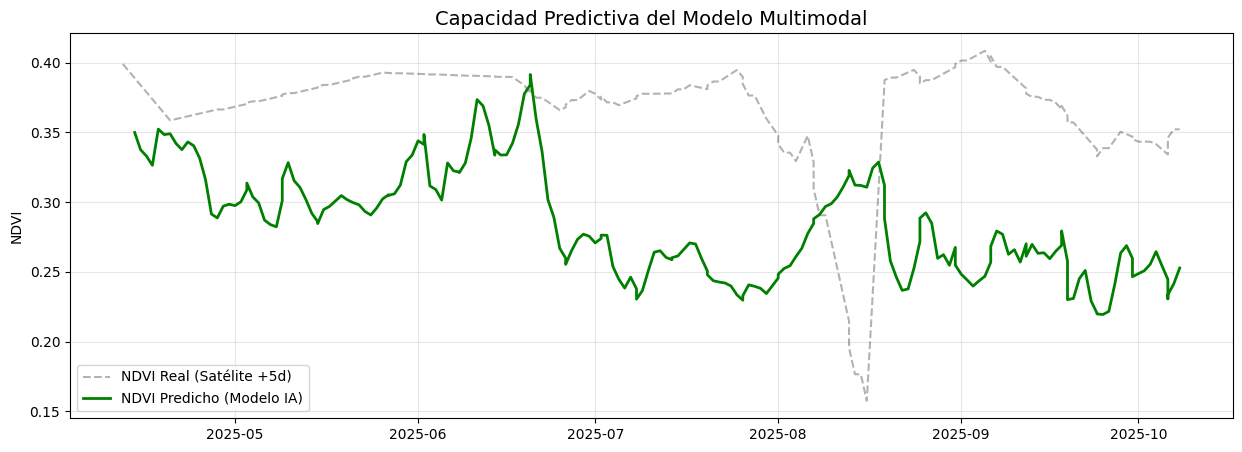

In [6]:
def plot_prediccion_vs_real(model, gen):
    preds, reals, fechas = [], [], []
    for i in range(len(gen)):
        inputs, targets = gen[i]
        p = model(inputs, training=False).numpy().flatten()
        preds.extend(p.tolist())
        reals.extend(targets.tolist())
        idx = i * gen.batch_size
        fechas.extend(pd.to_datetime(gen.df['Fecha'].iloc[idx : idx + len(p)]).tolist())
    
    df = pd.DataFrame({'Fecha': fechas, 'Real': reals, 'Pred': preds}).sort_values('Fecha')
    
    plt.figure(figsize=(15, 5))
    plt.plot(df['Fecha'], df['Real'], label='NDVI Real (Satélite +5d)', color='black', alpha=0.3, linestyle='--')
    plt.plot(df['Fecha'], df['Pred'].rolling(3).mean(), label='NDVI Predicho (Modelo IA)', color='green', linewidth=2)
    plt.title("Capacidad Predictiva del Modelo Multimodal", fontsize=14)
    plt.ylabel("NDVI")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

plot_prediccion_vs_real(model_ndvi, gen_val_limpio)

In [7]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

def explicar_sensores_detalle(model, gen, cols_tab, idx_muestra=0):
    n = len(gen.df)
    if idx_muestra < 0 or idx_muestra >= n:
        raise IndexError(f"idx_muestra fuera de rango: {idx_muestra} (n={n})")

    batch_size = gen.batch_size
    idx_batch = idx_muestra // batch_size
    idx_local = idx_muestra % batch_size

    inputs, _ = gen[idx_batch]

    tab_batch = inputs["Tabular_Input"]
    img_batch = inputs["Image_Input"]

    if len(tab_batch) == 0 or len(img_batch) == 0:
        raise ValueError(f"Batch vacío en gen[{idx_batch}]")

    tab_data = tf.convert_to_tensor(tab_batch[idx_local:idx_local+1], dtype=tf.float32)
    img_data = tf.convert_to_tensor(img_batch[idx_local:idx_local+1], dtype=tf.float32)

    with tf.GradientTape() as tape:
        tape.watch(tab_data)
        preds = model({"Tabular_Input": tab_data, "Image_Input": img_data}, training=False)

    grads = tape.gradient(preds, tab_data)
    if grads is None:
        raise ValueError("No se pudieron calcular gradientes para la rama tabular.")

    grads = grads.numpy()[0]
    atribucion = grads * tab_batch[idx_local]

    fecha = gen.df.iloc[idx_muestra]["Fecha"]
    plt.figure(figsize=(8, 4))
    plt.barh(cols_tab, atribucion, color="salmon")
    plt.title(f"Importancia de Sensores para el día {pd.to_datetime(fecha).date()}")
    plt.xlabel("Contribución a la predicción de NDVI")
    plt.tight_layout()
    plt.show()
    
    explicar_sensores_detalle(model_ndvi, gen_val_limpio, cols_tab, idx_muestra=10)



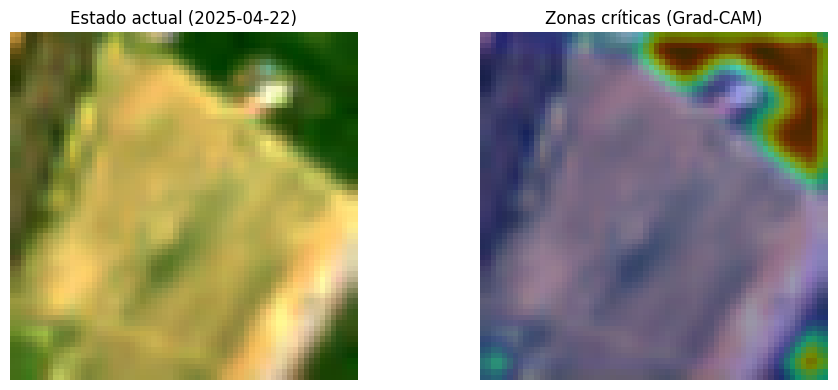

In [8]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import cv2
from tensorflow.keras import models

def visual_gradcam_ndvi(model, gen, idx_muestra=0, conv_layer_name="final_conv_layer"):
    n = len(gen.df)
    if idx_muestra < 0 or idx_muestra >= n:
        raise IndexError(f"idx_muestra fuera de rango: {idx_muestra} (n={n})")

    batch_size = gen.batch_size
    idx_batch = idx_muestra // batch_size
    idx_local = idx_muestra % batch_size

    inputs, _ = gen[idx_batch]
    tab_batch = inputs["Tabular_Input"]
    img_batch = inputs["Image_Input"]

    if len(tab_batch) == 0 or len(img_batch) == 0:
        raise ValueError(f"Batch vacío en gen[{idx_batch}]")

    t_tab = tf.convert_to_tensor(tab_batch[idx_local:idx_local+1], dtype=tf.float32)
    t_img = tf.convert_to_tensor(img_batch[idx_local:idx_local+1], dtype=tf.float32)

    grad_model = models.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_out, preds = grad_model({"Tabular_Input": t_tab, "Image_Input": t_img}, training=False)
        loss = preds[:, 0]

    grads = tape.gradient(loss, conv_out)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_map = conv_out[0]

    heatmap = tf.reduce_sum(conv_map * pooled_grads, axis=-1).numpy()
    heatmap = np.maximum(heatmap, 0)
    heatmap = heatmap / (np.max(heatmap) + 1e-10)

    img = img_batch[idx_local]
    heatmap_res = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
    heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap_res), cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    superposed = np.clip(0.6 * img + 0.4 * heatmap_color, 0, 1)

    fecha = gen.df.iloc[idx_muestra]["Fecha"]
    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1); plt.imshow(img); plt.title(f"Estado actual ({pd.to_datetime(fecha).date()})"); plt.axis("off")
    plt.subplot(1, 2, 2); plt.imshow(superposed); plt.title("Zonas críticas (Grad-CAM)"); plt.axis("off")
    plt.tight_layout()
    plt.show()
    
visual_gradcam_ndvi(model_ndvi, gen_val_limpio, idx_muestra=10)



In [9]:
import numpy as np

def simular_escenarios_riego(model, tabular_base, imagen_base, cols_tab):
    """
    tabular_base: (n_features,) o (1, n_features)
    imagen_base:  (H,W,C) o (1,H,W,C)
    """
    tab = np.asarray(tabular_base, dtype=np.float32)
    img = np.asarray(imagen_base, dtype=np.float32)

    # Forzar dimensión batch
    if tab.ndim == 1:
        tab = tab[None, :]
    if img.ndim == 3:
        img = img[None, :, :, :]

    if tab.ndim != 2:
        raise ValueError(f"Tabular con shape inválida: {tab.shape}")
    if img.ndim != 4:
        raise ValueError(f"Imagen con shape inválida: {img.shape}")

    idx_riego = cols_tab.index('Riego_mm')
    escenarios = [0, 10, 25]
    resultados = {}

    for mm in escenarios:
        t_sim = tab.copy()
        # Mantén la misma convención de escala que en tu notebook:
        t_sim[0, idx_riego] = mm / 10.0
        pred = model({"Tabular_Input": t_sim, "Image_Input": img}, training=False).numpy()[0][0]
        resultados[mm] = float(pred)

    return resultados


In [10]:
import numpy as np
import pandas as pd

def get_sample_from_generator(gen, idx_muestra_global):
    n = len(gen.df)
    if idx_muestra_global < 0 or idx_muestra_global >= n:
        raise IndexError(f"idx_muestra_global={idx_muestra_global} fuera de rango (n={n})")

    bsz = gen.batch_size
    idx_batch = idx_muestra_global // bsz
    idx_local = idx_muestra_global % bsz

    inputs, _ = gen[idx_batch]
    if len(inputs["Tabular_Input"]) == 0 or len(inputs["Image_Input"]) == 0:
        raise ValueError(f"Batch vacío en gen[{idx_batch}]")

    tab_sample = inputs["Tabular_Input"][idx_local]
    img_sample = inputs["Image_Input"][idx_local]
    return tab_sample, img_sample, idx_batch, idx_local


def generar_recomendacion_agronomica(fecha, resultados_sim, sensores_dict, ndvi_actual):
    """
    Traduce las simulaciones del modelo de Deep Learning a lenguaje natural técnico.
    """
    # Extraer valores de la simulación
    n0 = resultados_sim[0]
    n10 = resultados_sim[10]
    n25 = resultados_sim[25]
    
    # Lógica de tendencia
    tendencia = "descendente" if n0 < ndvi_actual else "estable"
    variacion = ((n0 - ndvi_actual) / ndvi_actual) * 100
    
    # Lógica de recomendación de cantidad
    # Buscamos dónde hay más ganancia de NDVI por cada mm de agua
    if n25 > n10 * 1.05: # Si subir a 25mm aporta mucho más que 10mm
        rec_mm = 25
        impacto = ((n25 - n0) / n0) * 100
    elif n10 > n0 * 1.02:
        rec_mm = 10
        impacto = ((n10 - n0) / n0) * 100
    else:
        rec_mm = 0
        impacto = 0

    # Redacción profesional (Simulando un LLM)
    texto = f"INFORME TÉCNICO - PARCELA SARDÓN DE DUERO - {fecha.date()}\n"
    texto += "-"*60 + "\n"
    
    if variacion < -2:
        texto += f"ADVERTENCIA: Se detecta una tendencia {tendencia} en el vigor vegetativo (NDVI) "
        texto += f"con una caída prevista del {abs(variacion):.1f}% en los próximos 5 días si se mantiene el secano.\n\n"
    else:
        texto += "ESTADO: El vigor vegetativo se mantiene estable bajo las condiciones climáticas actuales.\n\n"

    if rec_mm > 0:
        texto += f"RECOMENDACIÓN: Para optimizar la respuesta biológica y alcanzar un NDVI de {max(n10, n25):.2f}, "
        texto += f"se recomienda una aplicación de riego de {rec_mm} mm. "
        texto += f"Esta acción supone una mejora proyectada del {impacto:.1f}% respecto al escenario sin intervención."
    else:
        texto += "RECOMENDACIÓN: No se requiere intervención hídrica inmediata. El aporte de riego actual no muestra "
        texto += "incrementos significativos en la firma espectral del cultivo para el ciclo de 5 días analizado."

    return texto

# --- EJECUCIÓN ---
idx_muestra = 10  # índice global real en gen.df (no batch)
tab_sample, img_sample, idx_batch, idx_local = get_sample_from_generator(gen_val_limpio, idx_muestra)

resultados = simular_escenarios_riego(model_ndvi, tab_sample, img_sample, cols_tab)

fecha_hoy = gen_val_limpio.df.iloc[idx_muestra]["Fecha"]
ndvi_hoy = gen_val_limpio.df.iloc[idx_muestra]["Sat_NDVI"]

informe = generar_recomendacion_agronomica(
    fecha_hoy,
    resultados,
    dict(zip(cols_tab, tab_sample)),
    ndvi_hoy
)

print(f"Batch usado: {idx_batch}, muestra local: {idx_local}")
print(informe)



Batch usado: 0, muestra local: 10
INFORME TÉCNICO - PARCELA SARDÓN DE DUERO - 2025-04-22
------------------------------------------------------------
ADVERTENCIA: Se detecta una tendencia descendente en el vigor vegetativo (NDVI) con una caída prevista del 16.6% en los próximos 5 días si se mantiene el secano.

RECOMENDACIÓN: Para optimizar la respuesta biológica y alcanzar un NDVI de 0.33, se recomienda una aplicación de riego de 25 mm. Esta acción supone una mejora proyectada del 6.4% respecto al escenario sin intervención.
